# QR Heston SPX and VIX smiles from simulation

We use the quadratic rough hybrid scheme to generate SPX and VIX smiles 
for the four reference dates.

In [ ]:
# Run from either the repository root or R/.
if (!file.exists("fwd_var_curve.R")) setwd("R")
source("fwd_var_curve.R")
source("fukasawa_robust.R")

calibrations <- read.csv("../data/calibration_params.csv",
  colClasses = c(date = "character")
)
CALIB_DATES <- calibrations$date
COLORS <- c("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")
source("gamma_kernel.R")
source("qrh_gamma_y_from_xi.R")
source("qrh_simulation.R")
source("black_scholes.R")

options(repr.plot.width = 14, repr.plot.height = 19)


## Gamma kernel and initial forward variance curve

The gamma kernel is
$$\kappa(\tau)=\frac{\nu}{\Gamma(\alpha)}\,\tau^{\alpha-1}e^{-\lambda\tau},\qquad \alpha=H+\tfrac12.$$
The calibrated parameters satisfy the kernel convergence condition
$$\int_0^\infty\kappa(s)^2\,ds
=\frac{\nu^2\Gamma(2H)}{\Gamma(\alpha)^2(2\lambda)^{2H}}<1.$$

We infer $\xi_0$ from SPX variance swaps with smoothing `EPS = 0.03`, then recover
$$y_0(u)^2=\xi_0(u)-c-\int_0^u\xi_0(s)\,\kappa(u-s)^2\,ds.$$
Integration is performed using Gauss–Jacobi quadrature.

## Choose expiries and run simulations

- We choose identical SPX and VIX expiries: the first four VIX maturities for each date. 

- The paper settings are 300,000 paths and 300 time steps. For initial R tests,
we use `PATHS = 100000` and `STEPS = 100`. 

- The VIX averaging window is $30/365$ years.

In [2]:
PATHS <- 100000
STEPS <- 100
SEED <- 1234
EPS <- 0.03


In [3]:
panels <- list()
for (date in CALIB_DATES) {
    spx <- read.csv(paste0("../data/", date, "_spx_vol.csv"))
    vix <- read.csv(paste0("../data/", date, "_vix_vol.csv"))
    swaps <- varSwap.Robust(spx)
    xi <- xi.curve.smooth(
        swaps$expiries, swaps$vs.mid * swaps$expiries,
        eps = EPS
    )$xi.curve
    params <- as.list(calibrations[
        calibrations$date == date,
        c("al", "lam", "nu", "c")
    ])
    expiries <- head(sort(unique(vix$Texp)), 4)
    sim <- QRH.sim(params, xi, n_quad = 40)(
        paths = PATHS, steps = STEPS, expiries = expiries,
        output = "all", seed = SEED, nvix = 40, delvix = 30 / 365
    )
    for (asset in c("SPX", "VIX")) {
        quotes <- if (asset == "SPX") spx else vix
        for (i in seq_along(expiries)) {
            t <- expiries[i]
            d <- quotes[quotes$Texp == t & !is.na(quotes$Bid) & !is.na(quotes$Ask), ]
            spot <- if (asset == "SPX") exp(sim[[i]]$X) else sim[[i]]$vix
            d$k <- log(d$Strike / d$Fwd)
            # Price OTM options at strikes based on the sample forward,
            # matching Python's black_otm_impvol_mc. Zero sampled payoffs
            # have undefined implied volatilities and are omitted, as in Python.
            forward <- mean(spot)
            strikes <- forward * exp(d$k)
            d$model <- vapply(strikes, function(strike) {
                if (strike >= forward) {
                    price <- mean(pmax(spot - strike, 0))
                    if (price == 0) {
                        return(NA_real_)
                    }
                    BSImpliedVolCall(forward, strike, t, 0, price)
                } else {
                    price <- mean(pmax(strike - spot, 0))
                    if (price == 0) {
                        return(NA_real_)
                    }
                    BSImpliedVolPut(forward, strike, t, 0, price)
                }
            }, numeric(1))
            d$date <- date
            d$asset <- asset
            panels[[length(panels) + 1]] <- d
        }
    }
}
smiles <- do.call(rbind, panels)
rownames(smiles) <- NULL


Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”
Warning message:
“Forward variance fit did not converge: NEW_X. Returning the fitted curve.”


## SPX and VIX smiles

- For each date, the left four plots are SPX smiles and the right four are VIX smiles. 

- Red and blue points are bid and ask implied volatilities; green lines are model fits. 

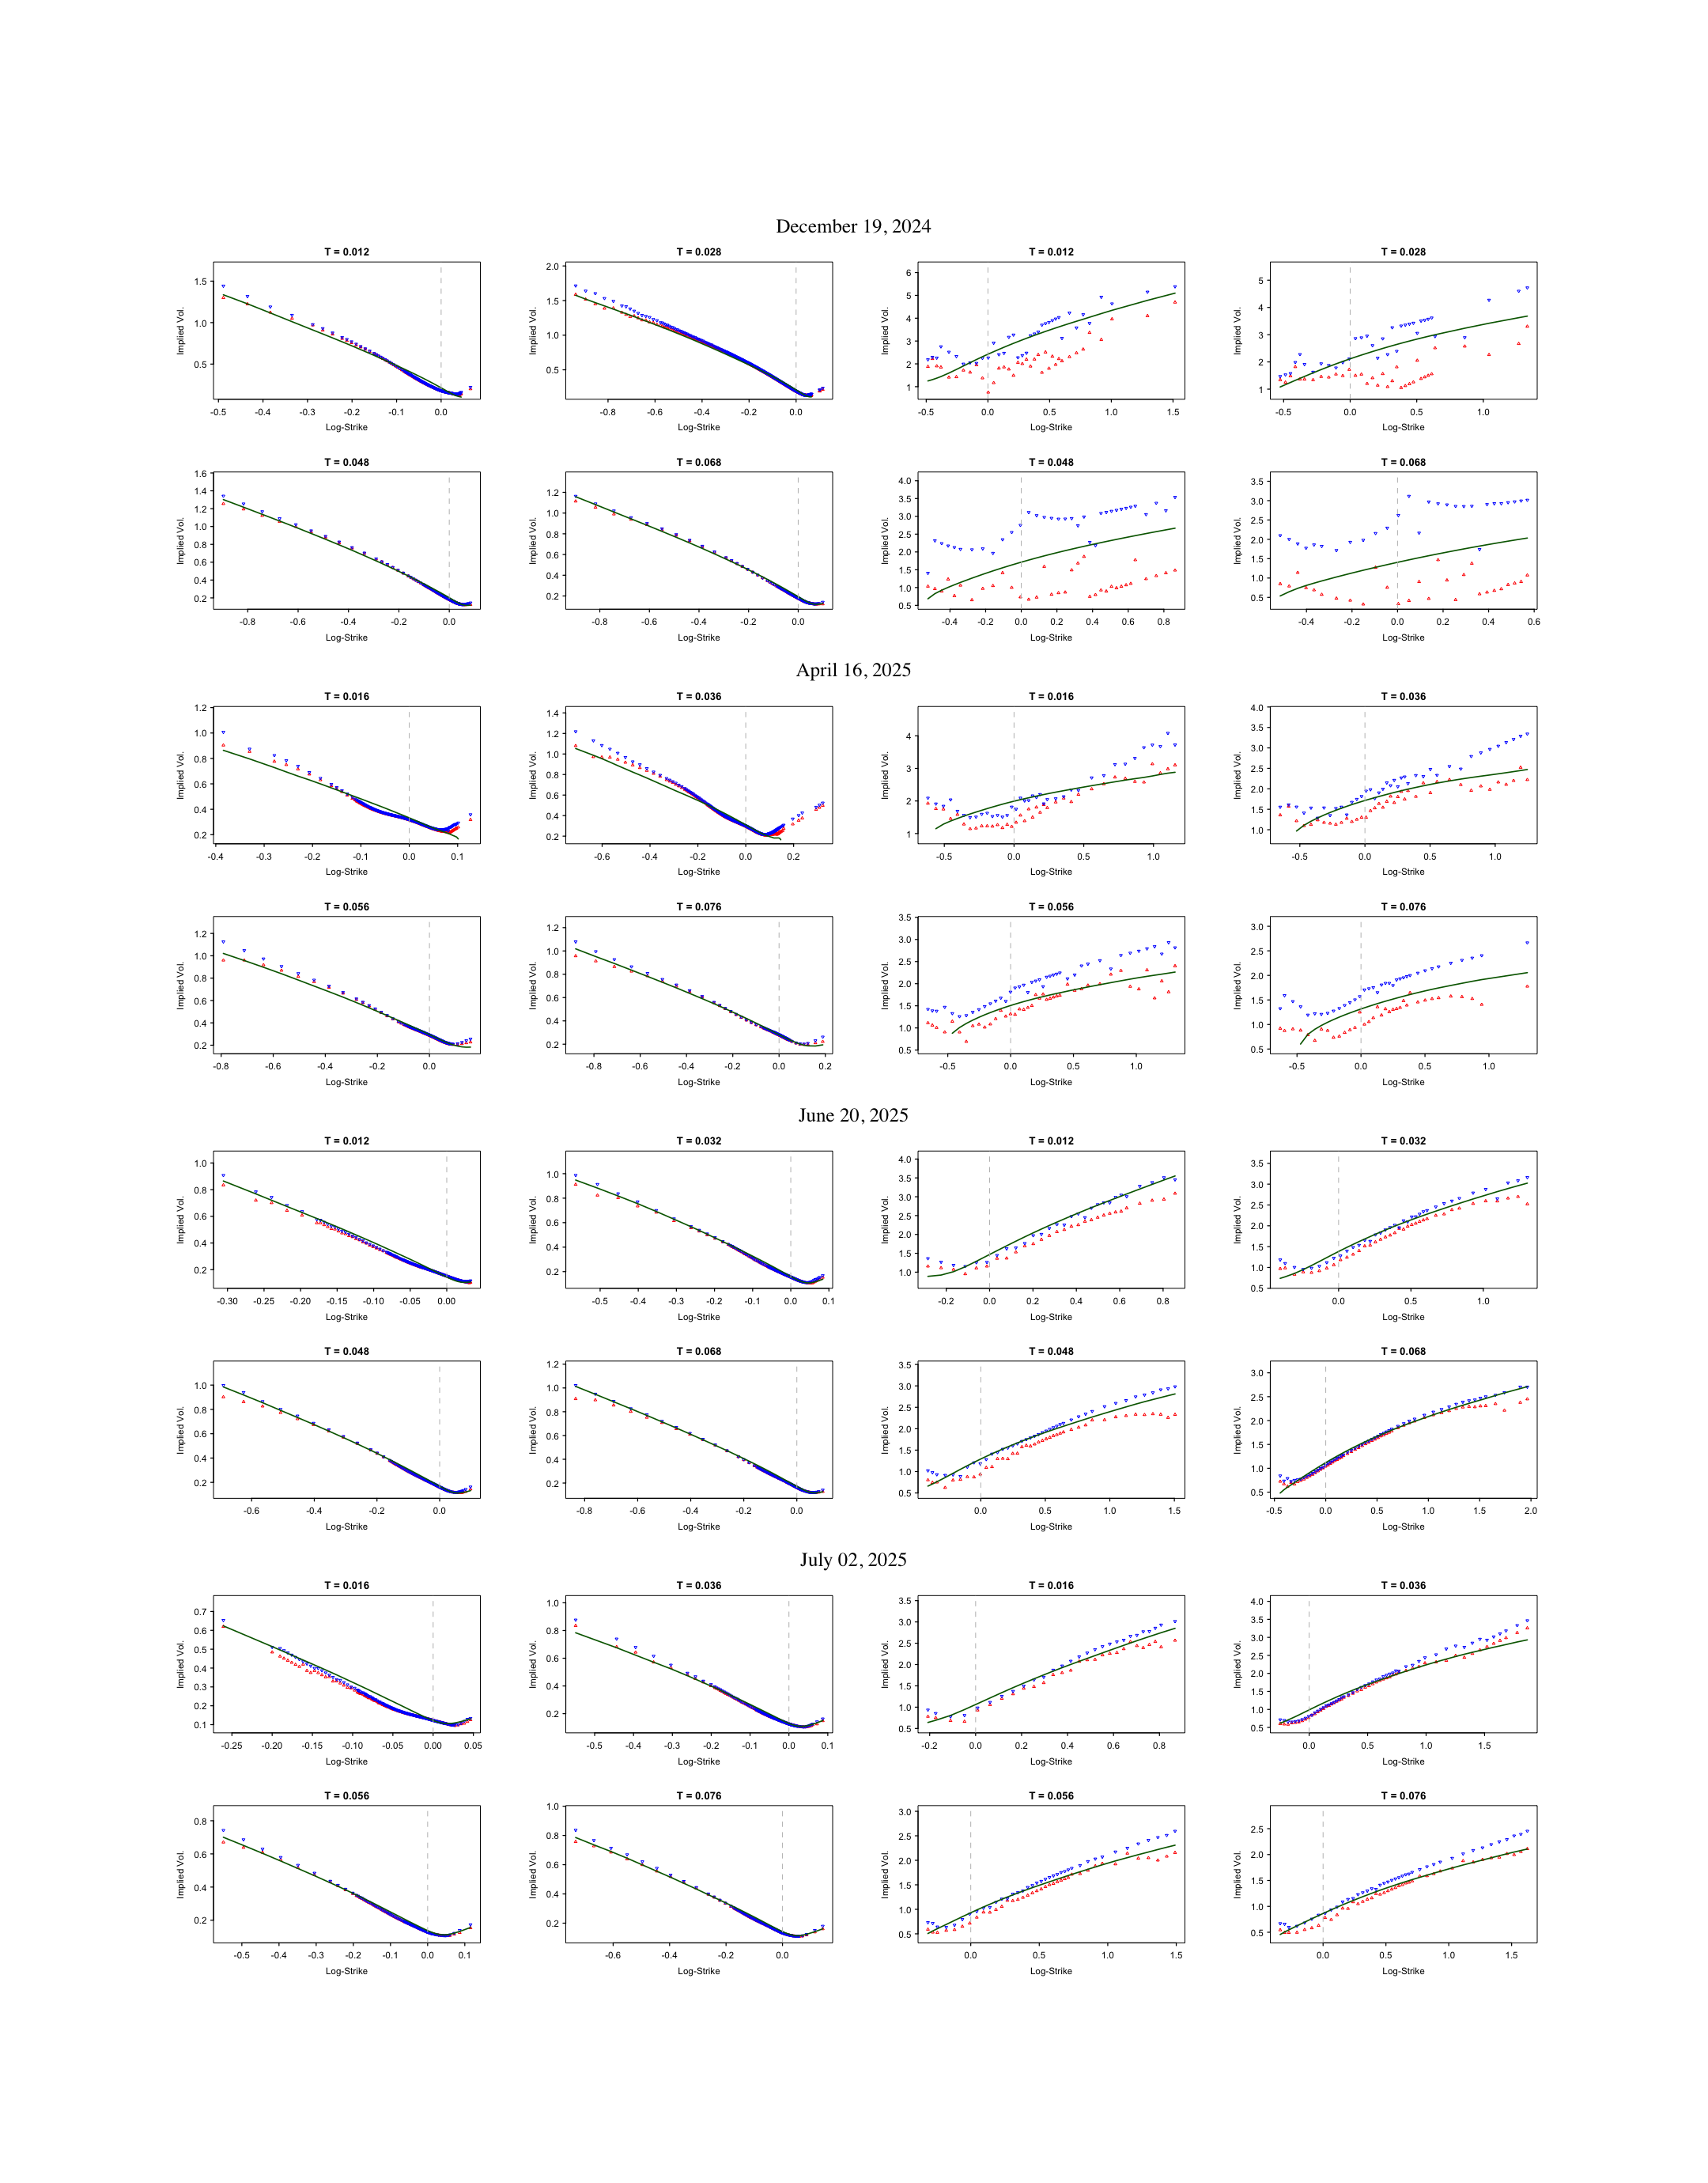

In [8]:
options(repr.plot.width = 18, repr.plot.height = 23)

par(bg = "white", mar = c(0, 0, 0, 0), ps = 12, cex = 1, xaxs = "i", yaxs = "i")
plot.new()
plot.window(xlim = c(0, 1), ylim = c(0, 1))
group.height <- (0.88 - 0.11) / (4 + 3 * 0.28)
panel.height <- group.height / (2 + 0.53)
panel.width <- (0.9 - 0.125) / (4 + 3 * 0.32)
for (row in seq_along(CALIB_DATES)) {
    date <- CALIB_DATES[row]
    top <- 0.88 - (row - 1) * group.height * 1.28
    # Draw the date heading in the full figure's coordinate system.
    par(cex = 1)
    par(fig = c(0, 1, 0, 1), mar = c(0, 0, 0, 0), new = TRUE)
    plot.new()
    plot.window(xlim = c(0, 1), ylim = c(0, 1))
    text(0.5, top + 0.016,
        format(as.Date(date, "%Y%m%d"), "%B %d, %Y"),
        cex = 15 / 12, family = "serif"
    )
    for (asset in c("SPX", "VIX")) {
        offset <- if (asset == "SPX") 0 else 2
        part <- smiles[smiles$date == date & smiles$asset == asset, ]
        expiries <- sort(unique(part$Texp))
        for (i in seq_along(expiries)) {
            t <- expiries[i]
            d <- part[part$Texp == t, ]
            d <- d[order(d$k), ]
            col <- offset + (i - 1) %% 2
            panel.row <- (i - 1) %/% 2
            left <- 0.125 + col * panel.width * 1.32
            upper <- top - panel.row * panel.height * 1.53
            par(cex = 7 / 12)
            par(
                fig = c(left, left + panel.width, upper - panel.height, upper),
                mar = c(0, 0, 0, 0), new = TRUE,
                lwd = 0.8, mgp = c(2, 0.6, 0), tcl = -0.25
            )
            include <- !is.na(d$Bid) & d$Bid > 0
            k.range <- range(d$k[include])
            kpad <- 0.04 * diff(k.range)
            plot(d$k, d$Bid,
                col = "red", pch = 24, bg = NA, cex = 0.5,
                xlim = k.range + c(-kpad, kpad),
                ylim = c(0.6 * min(d$Bid[include]), 1.2 * max(d$Ask[include])),
                xlab = "", ylab = "", las = 1
            )
            mtext("Log-Strike", side = 1, line = 2, cex = 7 / 12, xpd = NA)
            mtext("Implied Vol.", side = 2, line = 2.5, cex = 7 / 12, xpd = NA)
            points(d$k, d$Ask, col = "blue", pch = 25, bg = NA, cex = 0.5)
            lines(d$k, d$model, col = "darkgreen", lwd = 4 / 3)
            mtext(sprintf("T = %.3f", t),
                side = 3, line = 0.4,
                font = 2, cex = 8 / 12
            )
            abline(v = 0, h = 0, col = "gray", lty = 2, lwd = 0.8)
        }
    }
}
